# A6 · Detecting rare opportunities for encoder learning

**Complete** · 5/5 A5 feature sets · 24/24 independent hybrid trajectories

## Which event matters?

An action is feasible when its historical RankMe gain exceeds 0.1 of the seed’s A4.1 calibration scale and its reconstruction loss does not increase. A state is an opportunity if any encoder action qualifies. The A5 holdout contains **44 opportunity states on 18 distinct clips**. H0, H1, H4 and H16 contain 17, 12, 6 and 9 opportunities respectively, each among 1,152 states. States, horizons and actions that share a clip are correlated.

All six methods use the same A5 inputs within each comparison. M0 uses health and action descriptors. M1 adds x0 inference features. M2, M3 and M4 also see 1, 4 and 16 future frames. All horizons use the same 11 actions. Training uses the original 96 clips. Clips 1–72 fit the calibration models and 73–96 set a pooled rank-call threshold by F1 for selecting an actually feasible action. The final estimators fit all 96 clips. Clips 97–128 are the untouched A5 test split for model fitting and threshold selection.

| Method | What selects an action |
|---|---|
| B0 | Original A5 Extra Trees predictions and P5. |
| B1 | Same regression and P5. Positive raw RankMe gains receive inverse-frequency weight. |
| B2 | Balanced classifier for positive raw RankMe; only actions passing the predicted reconstruction guard may trigger. |
| B3 | Balanced classifier for the joint P5 feasibility event. |
| B4 | B3 probability times the predicted normalized RankMe gain conditional on feasibility. |
| B5 | Balanced state classifier predicting the direct P5 stage and action jointly. Its rank-class probabilities score each encoder action. |

B2–B4 fall back to B0’s reconstruction stage. B5 predicts its own fallback action. All methods use the recorded paired outcomes to score their final held-out choices. Recall counts opportunity states where the selected action meets **both** conditions. Precision counts such successes among **all selected encoder updates**. Rank-call precision uses only calls in the rank-first stage. AP is average precision (stepwise PR area); action AP excludes frozen encoders. Realized gains are mean raw-unit changes across all states, including Skip.

In [ ]:
import base64, gzip, io, json
from pathlib import Path
import numpy as np
from IPython.display import display, Markdown
name = 'MAE_A6_Rare_Event_Prediction.ipynb'
path = next(p for d in (Path.cwd(), *Path.cwd().parents) for p in (d/name, d/'project/cafl4ds/notebooks/selected/mae'/name) if p.is_file())
meta = json.loads(path.read_bytes())['metadata']['a6']
snapshot = json.loads(gzip.decompress(base64.b64decode(meta['snapshot'])))
def receipts(key):
    with np.load(io.BytesIO(base64.b64decode(meta[key])),allow_pickle=False) as f: return dict(f)


In [ ]:
"""Decision metrics from raw, paired A6 receipts. Positive loss gain means lower loss."""
import numpy as np
from sklearn.metrics import average_precision_score


def summary(raw, scales, enc, action, stage, scores, take):
    truth = raw[take]
    good = (truth[:, :, 1] > .1 * scales[take, 1, None]) & (truth[:, :, 0] >= 0) & enc
    action, stage = action[take], stage[take]
    ix = np.arange(len(action))
    outcomes = truth[ix, action]
    succeeded = good[ix, action]
    rank_call = stage == "rank"
    encoder = enc[action]
    ratio = lambda n, d: float(n/d) if d else None
    def ap(target, score):
        score = np.where(np.isfinite(score), score, -1e20)
        return float(average_precision_score(target.ravel(), score.ravel())) if target.any() else None
    opp = good.any(axis=1)
    s = scores[take][:, enc]
    return dict(states=len(action), opportunities=int(opp.sum()), hits=int(succeeded.sum()),
                encoder_updates=int(encoder.sum()), rank_calls=int(rank_call.sum()),
                recall=ratio(succeeded.sum(), opp.sum()), precision=ratio(succeeded.sum(), encoder.sum()),
                rank_precision=ratio((succeeded & rank_call).sum(), rank_call.sum()),
                state_ap=ap(opp, s.max(axis=1)), action_ap=ap(good[:, enc], s),
                prevalence=float(good[:, enc].mean()), rank_gain=float(outcomes[:, 1].mean()),
                loss_gain=float(outcomes[:, 0].mean()),
                encoder_rank_gain=float(outcomes[encoder, 1].mean()) if encoder.any() else None)


def table(rows, columns):
    def fmt(v):
        if v is None:
            return '—'
        if isinstance(v, float):
            return f'{v:.5g}'
        return str(v)
    lines = ['| ' + ' | '.join(columns) + ' |', '|' + '---|'*len(columns)]
    lines.extend('| ' + ' | '.join(fmt(row[k]) for k in columns) + ' |' for row in rows)
    return '\n'.join(lines)


In [ ]:
rows=[v for r in snapshot['results'] for v in r['rows']]
# Set h to 0, 1, 4 or 16 to inspect an individual reconstruction target.
h='all'
display(Markdown(table([v for v in rows if v['h']==h and v['features'] in ('M0','M4')],['features', 'model', 'hits', 'encoder_updates', 'recall', 'precision', 'rank_precision', 'state_ap', 'action_ap', 'rank_gain', 'loss_gain'])))

| features | model | hits | encoder_updates | recall | precision | rank_precision | state_ap | action_ap | rank_gain | loss_gain |
|---|---|---|---|---|---|---|---|---|---|---|
| M0 | B0 | 1 | 3 | 0.022727 | 0.33333 | — | 0.037981 | 0.011113 | 2.9583e-05 | 0.014804 |
| M0 | B1 | 4 | 759 | 0.090909 | 0.0052701 | 0 | 0.018271 | 0.0078086 | -0.0085083 | 0.014793 |
| M0 | B2 | 1 | 153 | 0.022727 | 0.0065359 | 0.0066225 | 0.035638 | 0.025072 | -0.00011699 | 0.014453 |
| M0 | B3 | 7 | 329 | 0.15909 | 0.021277 | 0.021407 | 0.040088 | 0.033412 | -0.0070138 | 0.014926 |
| M0 | B4 | 6 | 348 | 0.13636 | 0.017241 | 0.017341 | 0.022748 | 0.015491 | -0.027072 | 0.014679 |
| M0 | B5 | 17 | 2423 | 0.38636 | 0.0070161 | 0.013347 | 0.014726 | 0.0084854 | -0.070903 | 0.011294 |
| M4 | B0 | 0 | 1 | 0 | 0 | — | 0.012966 | 0.0032793 | -4.1133e-05 | 0.014829 |
| M4 | B1 | 2 | 219 | 0.045455 | 0.0091324 | — | 0.022634 | 0.0074955 | -0.0034555 | 0.014883 |
| M4 | B2 | 0 | 66 | 0 | 0 | 0 | 0.017236 | 0.00608 | -0.0001014 | 0.014676 |
| M4 | B3 | 6 | 121 | 0.13636 | 0.049587 | 0.05 | 0.042752 | 0.022154 | -0.0038891 | 0.014832 |
| M4 | B4 | 7 | 227 | 0.15909 | 0.030837 | 0.030837 | 0.051259 | 0.02554 | -0.02158 | 0.014737 |
| M4 | B5 | 13 | 934 | 0.29545 | 0.013919 | 0.020408 | 0.024861 | 0.012185 | -0.017777 | 0.013147 |

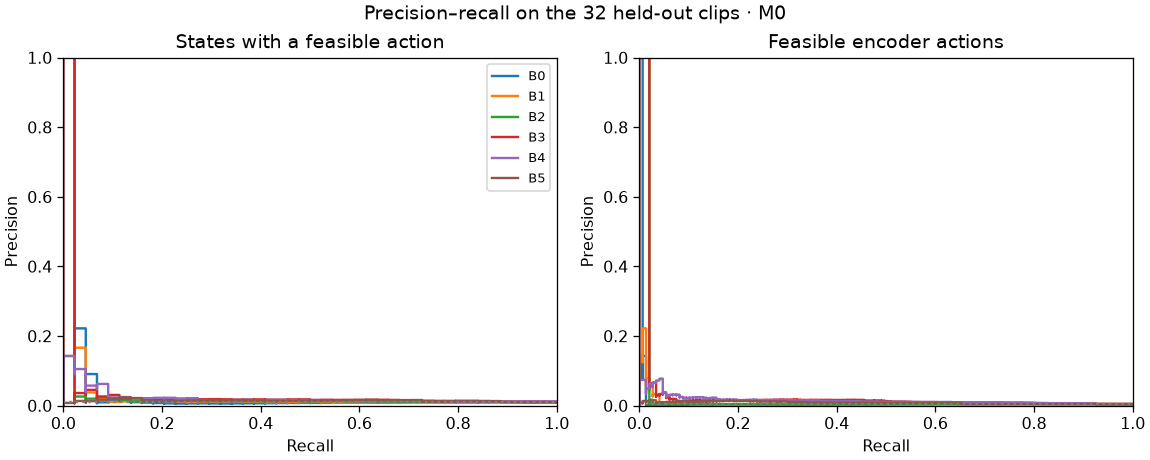

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
t=receipts('truth'); m=receipts('M0')
good=((t['y'][:,:,1]>.1*t['scales'][:,1,None])&(t['y'][:,:,0]>=0))[:,t['enc']]
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
for i in range(6):
    scores=m[f'B{i}_score'][:,t['enc']]
    scores=np.where(np.isfinite(scores),scores,-1e20)
    for ax,labels,values in [(axes[0],good.any(1),scores.max(1)),(axes[1],good.ravel(),scores.ravel())]:
        precision,recall,_=precision_recall_curve(labels,values)
        ax.step(recall,precision,where='post',label=f'B{i}')
for ax,labels,title in zip(axes,[good.any(1),good],['States with a feasible action','Feasible encoder actions']):
    ax.axhline(labels.mean(),ls=':',color='gray')
    ax.set(xlabel='Recall',ylabel='Precision',title=title,xlim=(0,1),ylim=(0,1))
axes[0].legend(fontsize=8);fig.suptitle('Precision–recall on the 32 held-out clips · M0')
plt.show()

In [ ]:
# Recalculate pooled decision metrics from raw targets and each selected action.
t=receipts('truth'); m=receipts('M0')
print(summary(t['y'],t['scales'],t['enc'],m['B3_action'],m['B3_stage'],m['B3_score'],np.ones(len(t['h']),bool)))

## Hybrid verification on held-out states

B3/M0 supplies the inexpensive decision. Verified states use the direct P5 action from all eleven measured branches. The mixed gate spends one fifth of its nominal verification budget on uniform exploration, with the remaining probability assigned to high-scoring states. Cutoffs and tie probabilities come from calibration clips separately for each horizon. Realized verification frequency can change on new clips. The 0% and 100% rows give the paired endpoints. These are replayed one-step effects.

In [ ]:
display(Markdown(table(snapshot['results'][0]['hybrid'],['budget', 'strategy', 'realized', 'found', 'opportunities', 'recall', 'precision', 'rank_gain', 'loss_gain'])))

| budget | strategy | realized | found | opportunities | recall | precision | rank_gain | loss_gain |
|---|---|---|---|---|---|---|---|---|
| 0 | mixed | 0 | 0 | 44 | 0.15909 | 0.021277 | -0.0070138 | 0.014926 |
| 0.05 | random | 0.049696 | 3 | 44 | 0.22727 | 0.030303 | -0.0066686 | 0.015066 |
| 0.05 | score | 0.084635 | 7 | 44 | 0.15909 | 0.12281 | 0.00040968 | 0.015096 |
| 0.05 | mixed | 0.065321 | 7 | 44 | 0.15909 | 0.056911 | -0.0010774 | 0.015016 |
| 0.25 | random | 0.2398 | 8 | 44 | 0.31818 | 0.046205 | -0.004596 | 0.015415 |
| 0.25 | score | 0.34896 | 27 | 44 | 0.61364 | 0.27 | 0.0033409 | 0.015754 |
| 0.25 | mixed | 0.3316 | 28 | 44 | 0.63636 | 0.27723 | 0.0033531 | 0.015732 |
| 0.5 | random | 0.49197 | 29 | 44 | 0.70455 | 0.11787 | -0.0010118 | 0.016039 |
| 0.5 | score | 0.61372 | 35 | 44 | 0.79545 | 0.22013 | 0.0038734 | 0.016397 |
| 0.5 | mixed | 0.59158 | 35 | 44 | 0.79545 | 0.22013 | 0.0037617 | 0.01627 |
| 1 | mixed | 1 | 44 | 44 | 1 | 0.22449 | 0.0042649 | 0.017196 |

## Timed continual test

Each controller starts from its A5 checkpoint and processes the same 128 prospective clips at base LR 0.001. Three seeds and H0/H16 are paired. Compare B3/M0 alone, 5% random verification, 5% score-based verification and the mixed 5% gate. Direct P5 references use the matching A5 runs. Wall-clock latency includes inference, selection, verification when triggered and commitment. Offline measurement of the selected outcome and fixed-cohort audits is excluded. Verified branch labels and pre-update features are retained for future training.

In [ ]:
live=[]
for r in snapshot['trajectories']:
    s=r['steps']
    live.append(dict(h=r['h'],seed=r['seed'],strategy=r['strategy'],budget=r['budget'],verified=sum(v['verified'] for v in s),mean_ms=float(np.mean([v['ms'] for v in s])),p95_ms=float(np.percentile([v['ms'] for v in s],95)),audit_rank_gain=r['final_rank']-r['initial_rank'],cohort_loss_gain=r['initial_loss']-r['final_loss']))
for r in snapshot['direct_reference']:
    live.append(dict(h=r['h'],seed=r['seed'],strategy='direct (A5)',budget=1.,verified=128,mean_ms=float(np.mean(r['ms'])),p95_ms=float(np.percentile(r['ms'],95)),audit_rank_gain=r['rank_gain'],cohort_loss_gain=r['loss_gain']))
display(Markdown(table(live,['h','seed','strategy','budget','verified','mean_ms','p95_ms','audit_rank_gain','cohort_loss_gain'])))

| h | seed | strategy | budget | verified | mean_ms | p95_ms | audit_rank_gain | cohort_loss_gain |
|---|---|---|---|---|---|---|---|---|
| 0 | 2026 | mixed | 0.05 | 52 | 191.27 | 449.43 | 0 | 0.052743 |
| 0 | 2026 | mixed | 0 | 0 | 22.922 | 27.85 | -0.30803 | 0.048826 |
| 0 | 2026 | random | 0.05 | 6 | 41.86 | 59.873 | -0.30803 | 0.049384 |
| 0 | 2026 | score | 0.05 | 55 | 196.65 | 461.04 | 0 | 0.052743 |
| 16 | 2026 | mixed | 0.05 | 17 | 75.746 | 416.46 | 0.015162 | 0.049615 |
| 16 | 2026 | mixed | 0 | 0 | 24.251 | 31.87 | -0.27126 | 0.048049 |
| 16 | 2026 | random | 0.05 | 6 | 42.561 | 32.745 | -0.26808 | 0.048618 |
| 16 | 2026 | score | 0.05 | 13 | 64.064 | 411.41 | 0.050325 | 0.03876 |
| 0 | 2027 | mixed | 0.05 | 4 | 35.684 | 33.94 | 0 | 0.033432 |
| 0 | 2027 | mixed | 0 | 0 | 23.849 | 31.499 | -0.18474 | 0.035273 |
| 0 | 2027 | random | 0.05 | 11 | 56.606 | 398.26 | -0.18474 | 0.032763 |
| 0 | 2027 | score | 0.05 | 1 | 26.425 | 25.225 | 0 | 0.032234 |
| 16 | 2027 | mixed | 0.05 | 4 | 35.07 | 27.514 | 0 | 0.034489 |
| 16 | 2027 | mixed | 0 | 0 | 23.246 | 30.88 | -0.18474 | 0.035273 |
| 16 | 2027 | random | 0.05 | 11 | 57.003 | 404.44 | -0.18474 | 0.029821 |
| 16 | 2027 | score | 0.05 | 1 | 27.191 | 24.615 | 0 | 0.032234 |
| 0 | 2028 | mixed | 0.05 | 9 | 54.18 | 414.15 | 0 | 0.050651 |
| 0 | 2028 | mixed | 0 | 0 | 24.463 | 32.235 | -0.37522 | 0.053305 |
| 0 | 2028 | random | 0.05 | 6 | 43.296 | 59.271 | -0.37522 | 0.053823 |
| 0 | 2028 | score | 0.05 | 8 | 49.293 | 402.71 | 0 | 0.051262 |
| 16 | 2028 | mixed | 0.05 | 8 | 48.762 | 402.45 | 0.056392 | 0.052403 |
| 16 | 2028 | mixed | 0 | 0 | 23.591 | 30.02 | -0.37522 | 0.053305 |
| 16 | 2028 | random | 0.05 | 6 | 43.837 | 48.312 | -0.37522 | 0.053305 |
| 16 | 2028 | score | 0.05 | 16 | 74.79 | 437.69 | 0.070821 | 0.047848 |
| 0 | 2026 | direct (A5) | 1 | 128 | 404.99 | 467.53 | 0.0079837 | 0.020886 |
| 16 | 2026 | direct (A5) | 1 | 128 | 407.11 | 464.2 | 0.20013 | 0.013037 |
| 0 | 2027 | direct (A5) | 1 | 128 | 408.32 | 454.4 | 0 | 0.0117 |
| 16 | 2027 | direct (A5) | 1 | 128 | 408.26 | 451.73 | 0 | 0.013495 |
| 0 | 2028 | direct (A5) | 1 | 128 | 409.63 | 462.53 | 0.57899 | 0.010288 |
| 16 | 2028 | direct (A5) | 1 | 128 | 411.32 | 465.03 | 0.24739 | 0.019633 |